## Import Libraries

In [44]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from math import pi
from sklearn.model_selection import cross_val_score, StratifiedKFold
from xgboost import XGBClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, roc_auc_score, precision_score, recall_score, f1_score

## Load the Dataset


In [45]:
df = pd.read_csv("C:/Users/rache/Downloads/Parkinsson__disease.csv")
df.head()

,name,MDVP:Fo(Hz),MDVP:Fhi(Hz),MDVP:Flo(Hz),MDVP:Jitter(%),MDVP:Jitter(Abs),MDVP:RAP,MDVP:PPQ,Jitter:DDP,MDVP:Shimmer,...,Shimmer:DDA,NHR,HNR,status,RPDE,DFA,spread1,spread2,D2,PPE
0,phon_R01_S01_1,119.992,157.302,74.997,0.00784,0.00007,0.00370,0.00554,0.01109,0.04374,...,0.06545,0.02211,21.033,1,0.414783,0.815285,-4.813031,0.266482,2.301442,0.284654
1,phon_R01_S01_2,122.400,148.650,113.819,0.00968,0.00008,0.00465,0.00696,0.01394,0.06134,...,0.09403,0.01929,19.085,1,0.458359,0.819521,-4.075192,0.335590,2.486855,0.368674
2,phon_R01_S01_3,116.682,131.111,111.555,0.01050,0.00009,0.00544,0.00781,0.01633,0.05233,...,0.08270,0.01309,20.651,1,0.429895,0.825288,-4.443179,0.311173,2.342259,0.332634
3,phon_R01_S01_4,116.676,137.871,111.366,0.00997,0.00009,0.00502,0.00698,0.01505,0.05492,...,0.08771,0.01353,20.644,1,0.434969,0.819235,-4.117501,0.334147,2.405554,0.368975
4,phon_R01_S01_5,116.014,141.781,110.655,0.01284,0.00011,0.00655,0.00908,0.01966,0.06425,...,0.10470,0.01767,19.649,1,0.417356,0.823484,-3.747787,0.234513,2.332180,0.410335


In [46]:
df.shape

(195, 24)

## Exploratory Data Analysis (EDA)

In [47]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 195 entries, 0 to 194
Data columns (total 24 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   name              195 non-null    object 
 1   MDVP:Fo(Hz)       195 non-null    float64
 2   MDVP:Fhi(Hz)      195 non-null    float64
 3   MDVP:Flo(Hz)      195 non-null    float64
 4   MDVP:Jitter(%)    195 non-null    float64
 5   MDVP:Jitter(Abs)  195 non-null    float64
 6   MDVP:RAP          195 non-null    float64
 7   MDVP:PPQ          195 non-null    float64
 8   Jitter:DDP        195 non-null    float64
 9   MDVP:Shimmer      195 non-null    float64
 10  MDVP:Shimmer(dB)  195 non-null    float64
 11  Shimmer:APQ3      195 non-null    float64
 12  Shimmer:APQ5      195 non-null    float64
 13  MDVP:APQ          195 non-null    float64
 14  Shimmer:DDA       195 non-null    float64
 15  NHR               195 non-null    float64
 16  HNR               195 non-null    float64
 1

In [48]:
# Mengubah nama kolom untuk menghapus karakter unik
df.columns = df.columns.str.replace('[^A-Za-z0-9_]+', '', regex=True)

In [49]:
df.describe()

,MDVPFoHz,MDVPFhiHz,MDVPFloHz,MDVPJitter,MDVPJitterAbs,MDVPRAP,MDVPPPQ,JitterDDP,MDVPShimmer,MDVPShimmerdB,...,ShimmerDDA,NHR,HNR,status,RPDE,DFA,spread1,spread2,D2,PPE
count,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,...,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000
mean,154.228641,197.104918,116.324631,0.006220,0.000044,0.003306,0.003446,0.009920,0.029709,0.282251,...,0.046993,0.024847,21.885974,0.753846,0.498536,0.718099,-5.684397,0.226510,2.381826,0.206552
std,41.390065,91.491548,43.521413,0.004848,0.000035,0.002968,0.002759,0.008903,0.018857,0.194877,...,0.030459,0.040418,4.425764,0.431878,0.103942,0.055336,1.090208,0.083406,0.382799,0.090119
min,88.333000,102.145000,65.476000,0.001680,0.000007,0.000680,0.000920,0.002040,0.009540,0.085000,...,0.013640,0.000650,8.441000,0.000000,0.256570,0.574282,-7.964984,0.006274,1.423287,0.044539
25%,117.572000,134.862500,84.291000,0.003460,0.000020,0.001660,0.001860,0.004985,0.016505,0.148500,...,0.024735,0.005925,19.198000,1.000000,0.421306,0.674758,-6.450096,0.174351,2.099125,0.137451
50%,148.790000,175.829000,104.315000,0.004940,0.000030,0.002500,0.002690,0.007490,0.022970,0.221000,...,0.038360,0.011660,22.085000,1.000000,0.495954,0.722254,-5.720868,0.218885,2.361532,0.194052
75%,182.769000,224.205500,140.018500,0.007365,0.000060,0.003835,0.003955,0.011505,0.037885,0.350000,...,0.060795,0.025640,25.075500,1.000000,0.587562,0.761881,-5.046192,0.279234,2.636456,0.252980
max,260.105000,592.030000,239.170000,0.033160,0.000260,0.021440,0.019580,0.064330,0.119080,1.302000,...,0.169420,0.314820,33.047000,1.000000,0.685151,0.825288,-2.434031,0.450493,3.671155,0.527367


### Check for Missing Values

In [50]:
df.isnull().sum().sum()

np.int64(0)

### Check for Duplicate Values

In [51]:
df.duplicated().sum()

np.int64(0)

### Target Variable Distribution

In [52]:
df['status'].value_counts()

status
1    147
0     48
Name: count, dtype: int64

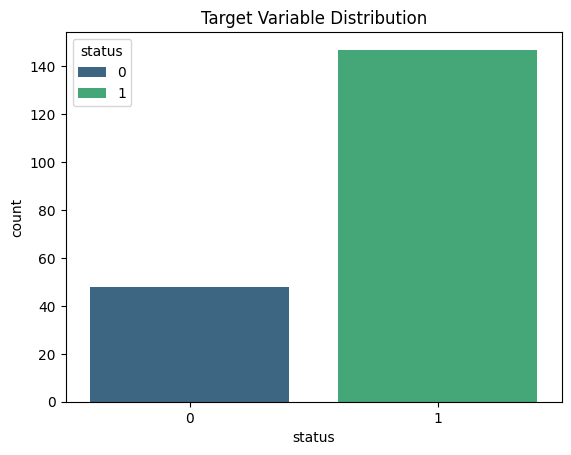

In [53]:
# Visualisasi distribusi nilai target
sns.countplot(x='status', data=df, palette='viridis', hue='status')
plt.title('Target Variable Distribution')
plt.show()

## Feature Selection

### Remove Unnecessary Columns

In [54]:
# Hapus kolom nama
df.drop('name', axis=1, inplace=True)

### Separate Features and Target

In [55]:
# Memisahkan features dan target
X = df.drop(columns=['status'])  # Pengecualian kolom target
y = df['status']

### Remove Highly Correlated Features

In [56]:
# Menghitung matrix korelasi
correlation_matrix = X.corr().abs()

# Memilih upper triangle dari matrix korelasi
upper_triangle = correlation_matrix.where(
    np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool)
)

# Menemukan features dengan nilai korelasi > 0.9
to_drop = [column for column in upper_triangle.columns if any(upper_triangle[column] > 0.9)]

# Menghapus features dengan korelasi tinggi
X = X.drop(columns=to_drop)
print(f"Dropped columns: {to_drop}")

Dropped columns: ['MDVPJitterAbs', 'MDVPRAP', 'MDVPPPQ', 'JitterDDP', 'MDVPShimmerdB', 'ShimmerAPQ3', 'ShimmerAPQ5', 'MDVPAPQ', 'ShimmerDDA', 'NHR', 'PPE']


### Feature Correlation

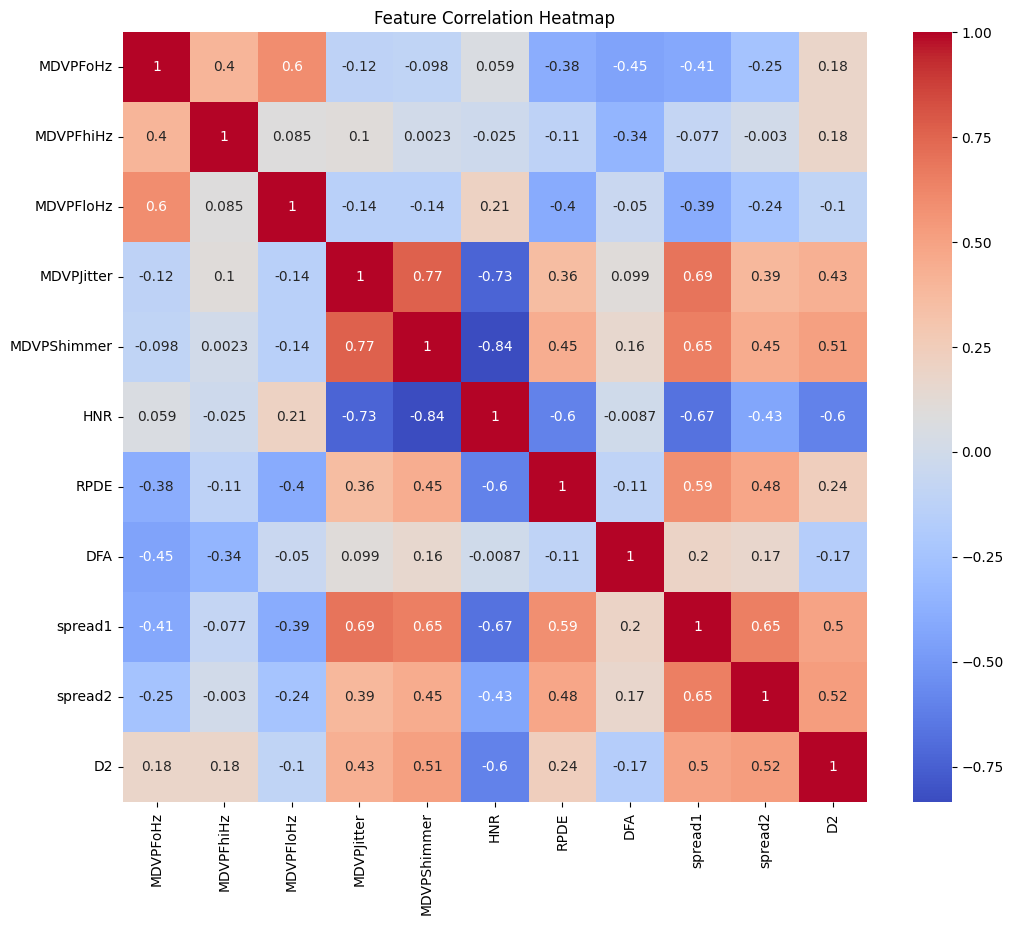

In [57]:
# Visualisasi feature correlation
plt.figure(figsize=(12, 10))
sns.heatmap(X.corr(), cmap='coolwarm', annot=True)
plt.title('Feature Correlation Heatmap')
plt.show()

## Model Training and Evaluation

In [58]:
# Inisialisasi skema Cross Validation
skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

# Inisialisasi model
models = {
    "Random Forest": RandomForestClassifier(random_state=42),
    "XGBoost": XGBClassifier(eval_metric='logloss', random_state=42)
}

# Evaluasi masing-masing model
for name, model in models.items():
    acc_scores = cross_val_score(model, X, y, cv=skf, scoring='accuracy')
    f1_scores = cross_val_score(model, X, y, cv=skf, scoring='f1')
    roc_auc_scores = cross_val_score(model, X, y, cv=skf, scoring='roc_auc')
    precision_scores = cross_val_score(model, X, y, cv=skf, scoring='precision')
    recall_scores = cross_val_score(model, X, y, cv=skf, scoring='recall')
    
    print(f"\n{name} 10-Fold Cross-Validation Results:")
    print(f"Mean Accuracy     : {acc_scores.mean():.4f}")
    print(f"Mean F1 Score     : {f1_scores.mean():.4f}")
    print(f"Mean ROC AUC Score: {roc_auc_scores.mean():.4f}")
    print(f"Mean Precision    : {precision_scores.mean():.4f}")
    print(f"Mean Recall       : {recall_scores.mean():.4f}")



Random Forest 10-Fold Cross-Validation Results:
Mean Accuracy     : 0.9074
Mean F1 Score     : 0.9410
Mean ROC AUC Score: 0.9643
Mean Precision    : 0.9199
Mean Recall       : 0.9662

XGBoost 10-Fold Cross-Validation Results:
Mean Accuracy     : 0.9171
Mean F1 Score     : 0.9466
Mean ROC AUC Score: 0.9509
Mean Precision    : 0.9238
Mean Recall       : 0.9724


## Results Comparison


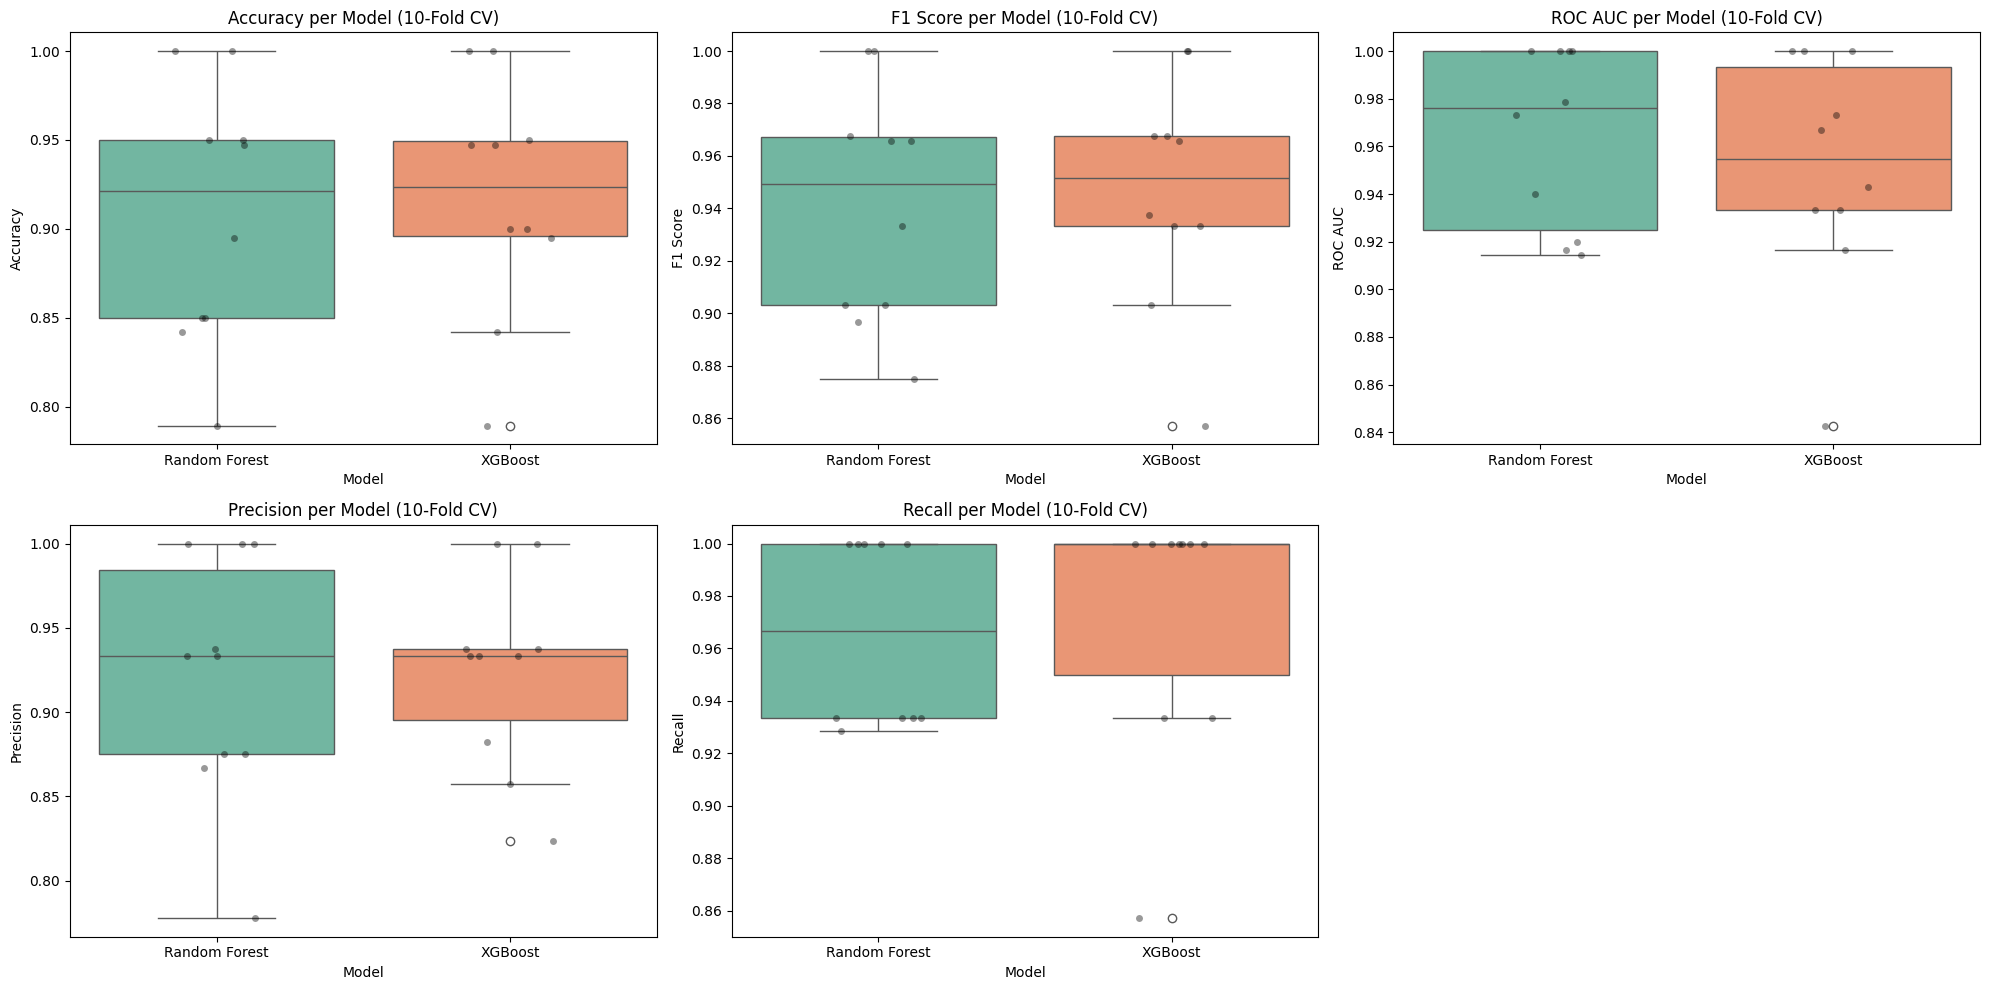

In [59]:
# Skor yang ingin dihitung
scoring_metrics = {
    "Accuracy": "accuracy",
    "F1 Score": "f1",
    "ROC AUC": "roc_auc",
    "Precision": "precision",
    "Recall": "recall"
}

# Simpan skor ke list
cv_results = []

for name, model in models.items():
    # Hitung semua metrik
    scores = {
        metric: cross_val_score(model, X, y, cv=skf, scoring=scorer)
        for metric, scorer in scoring_metrics.items()
    }
    # Gabungkan hasil setiap fold
    for fold in range(skf.get_n_splits()):
        result = {"Model": name, "Fold": fold + 1}
        result.update({metric: scores[metric][fold] for metric in scoring_metrics})
        cv_results.append(result)

# Konversi ke DataFrame
cv_df = pd.DataFrame(cv_results)

# Visualisasi semua metrik
plt.figure(figsize=(20, 10))
for i, metric in enumerate(scoring_metrics.keys()):
    plt.subplot(2, 3, i+1)
    sns.boxplot(data=cv_df, x='Model', y=metric, hue='Model', palette='Set2', legend=False)
    sns.stripplot(data=cv_df, x='Model', y=metric, color='black', alpha=0.4, jitter=0.15)
    plt.title(f'{metric} per Model (10-Fold CV)')
    plt.ylabel(metric)
    plt.xlabel('Model')

plt.tight_layout()
plt.show()

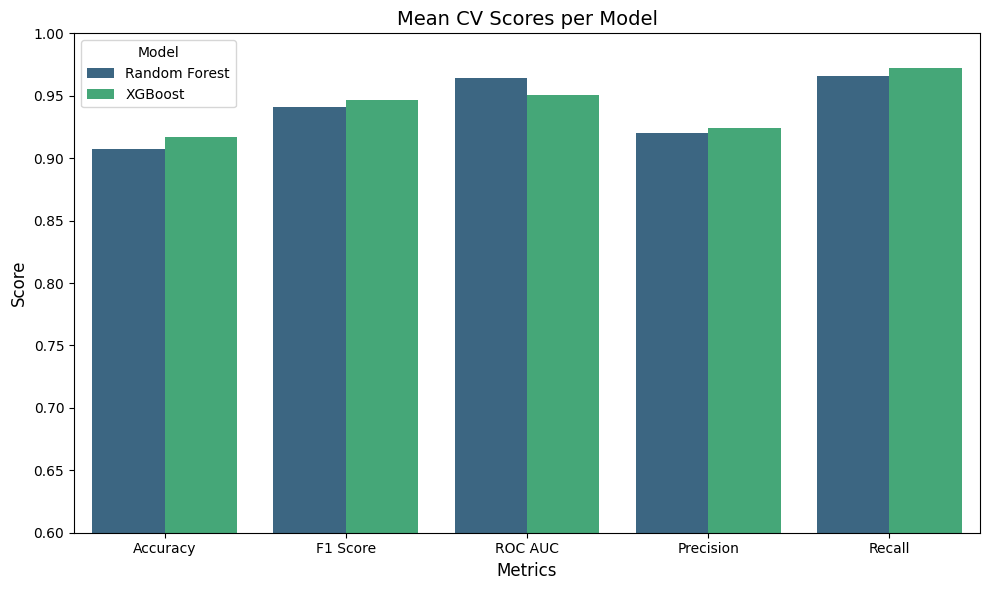

In [60]:
# Hitung rata-rata hanya untuk kolom metrik
cv_mean_df = cv_df.groupby("Model")[["Accuracy", "F1 Score", "ROC AUC", "Precision", "Recall"]].mean().reset_index()

# Ubah ke format long
melted_cv = cv_mean_df.melt(id_vars="Model", var_name="Metric", value_name="Value")

# Plot bar chart
plt.figure(figsize=(10, 6))
sns.barplot(data=melted_cv, x="Metric", y="Value", hue="Model", palette="viridis")
plt.title("Mean CV Scores per Model", fontsize=14)
plt.xlabel("Metrics", fontsize=12)
plt.ylabel("Score", fontsize=12)
plt.ylim(0.6, 1.0)
plt.legend(title="Model")
plt.tight_layout()
plt.show()


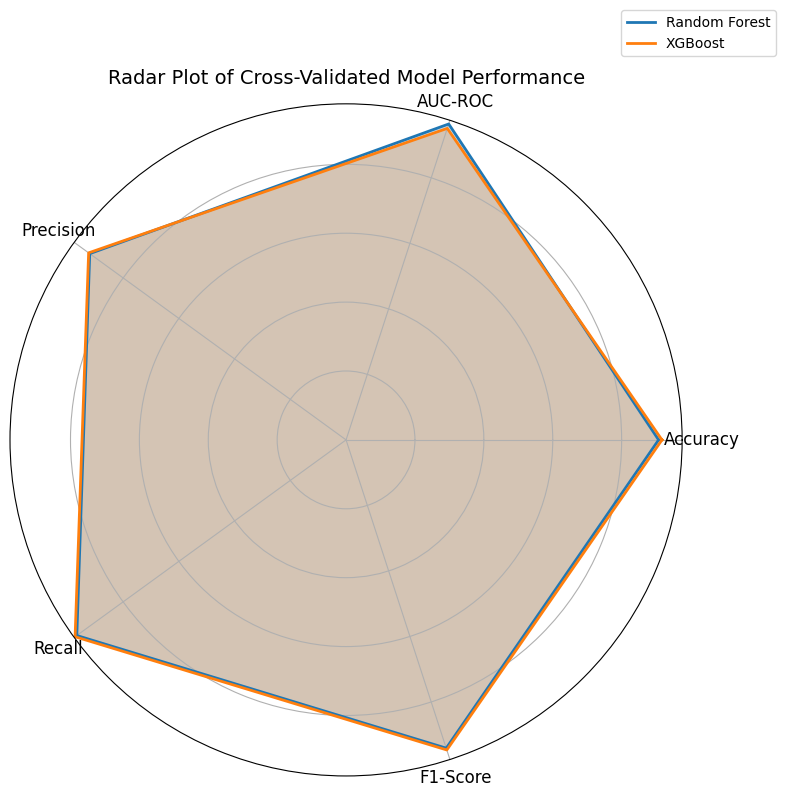

In [61]:
# Ambil rata-rata dari setiap metrik per model (dari cv_df)
cv_mean_df = cv_df.groupby("Model")[["Accuracy", "ROC AUC", "Precision", "Recall", "F1 Score"]].mean().reset_index()

# Ubah nama kolom agar konsisten dengan label radar chart
cv_mean_df.columns = ['Model', 'Accuracy', 'AUC-ROC', 'Precision', 'Recall', 'F1-Score']

# Fungsi radar chart
def plot_spider_chart(df):
    labels = ['Accuracy', 'AUC-ROC', 'Precision', 'Recall', 'F1-Score']
    num_vars = len(labels)

    # Hitung sudut untuk tiap sumbu
    angles = np.linspace(0, 2 * np.pi, num_vars, endpoint=False).tolist()
    angles += angles[:1]

    # Setup plot
    fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))

    for model_name in df['Model'].unique():
        values = df[df['Model'] == model_name].iloc[0, 1:].values
        values = np.concatenate((values, [values[0]]))  # Tutup lingkaran
        ax.plot(angles, values, linewidth=2, linestyle='solid', label=model_name)
        ax.fill(angles, values, alpha=0.25)

    ax.set_yticklabels([])
    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(labels, fontsize=12)
    ax.set_title("Radar Plot of Cross-Validated Model Performance", size=14)
    plt.legend(loc='upper right', bbox_to_anchor=(1.15, 1.15))
    plt.tight_layout()
    plt.show()

# Panggil fungsi dengan mean CV result
plot_spider_chart(cv_mean_df)
